In [2]:
# Prerequisites
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams["figure.dpi"] = 300
plt.rcParams["figure.figsize"] = (12, 3)

In [3]:
from ponds import PONDS, BLOB, SIGMOID, Trend, Lorenz

# Generating a dataset of timeseries that include nonlinear shifts

With ponds, this is done by *first* creating a regular dataset of timeseries that will serve as the forcing and *then* feed that dataset as a whole into a dynamical system that would show nonlinear dynamics. 

We can tweak PONDS core methods a bit to serve this purpose, and finally use `PONDS.apply_transformation()` to generate dataset.

## 1. Create a ponds object and choose a dynamical system

Note: Yet, only the Lorenz system is implemented, and can be forced through the beta parameter.

In [4]:
pond = PONDS(
    lat_size=20,
    lon_size=40,
    time_size=2000
)

# instantiate a dynamical system and choose forced parameter
system = Lorenz(forced_parameter='beta')

## 2. Set the ground state 

In our ponds object, set ground state where all added shifts would depart from. This can be realized by retrieving the respective parameter value from our system, and then adding that as a constant to our dataset using `Trend`:

In [5]:
ground_state = 'p1'                     # periodic state
ground_value = system.get_parameter_value(state=ground_state)

pond.add_perturbation(                  # better call this "add_background"?
    perturbation_method=Trend(
        slope=0,
        intercept=ground_value,
    )
)

## 3. Add some shifts to the dataset

For each shift, choose what state the system should shift to from the states stored in `system.get_parameter_value()`.

In [6]:
# add shift-blob with custom parameters
shifted_state = 'c1'                    # chaotic state
shifted_value = system.get_parameter_value(state=shifted_state)

shift_dict = {
    "shift_steepness": 0.2,
    "shift_magnitude": shifted_value - ground_value,
}
pond.add_shift(
    shape_method=BLOB(random_seed=4),
    shift_method=SIGMOID(**shift_dict),
)


# add another shift-blob with custom parameters
shifted_state = 'c2'                    # different chaotic state
shifted_value = system.get_parameter_value(state=shifted_state)

shift_dict = {
    "shift_steepness": 0.2,
    "shift_magnitude": shifted_value - ground_value,
}
pond.add_shift(
    shape_method=BLOB(random_seed=2),
    shift_method=SIGMOID(**shift_dict),
)

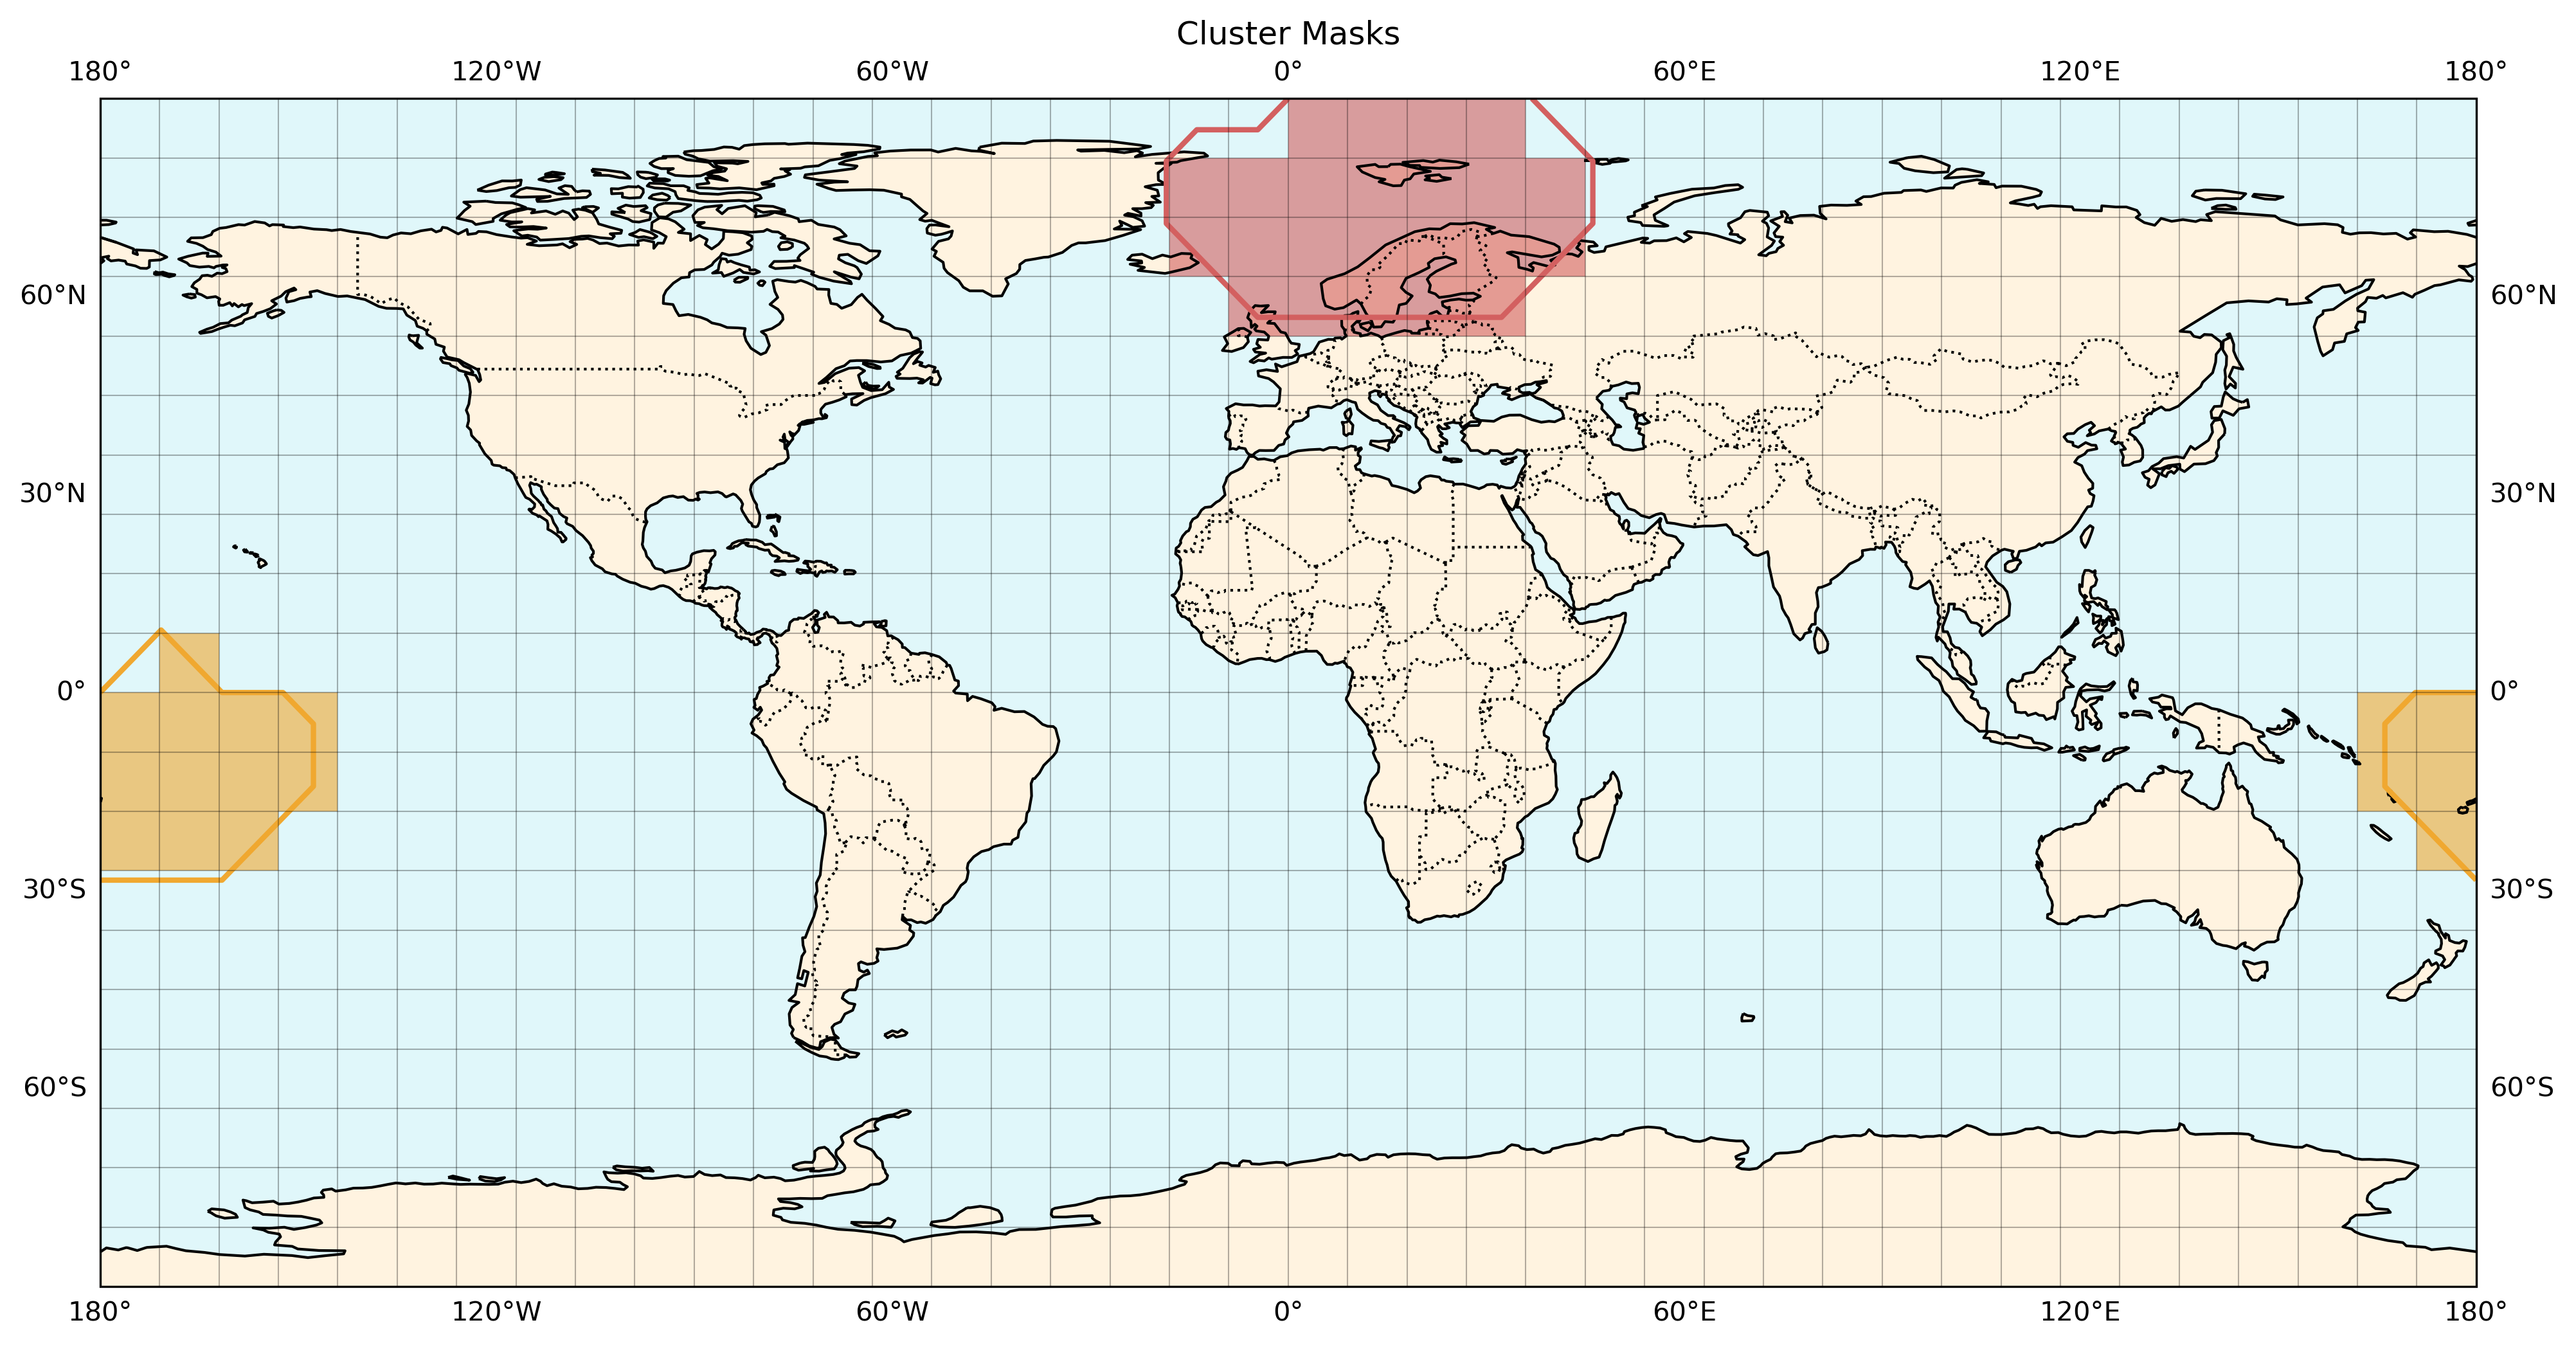

In [7]:
# look at the generated synthetic data
pond.worldmap(show_cells=True)

## 4. Feed dataset into the chosen dynamical System

Now our dataset of shifting timeseries can be transformed by a dynamical system such as the Lorenz system to obtain a set of timeseries with nonlinear shifts. This is done with `PONDS.apply_transformation()`.

In [8]:
pond.apply_transformation(
    system=system,
    dt=1e-4,
    sampling_factor=500
)

Integrating Lorenz system:   0%|          | 0/1999 [00:00<?, ? timesteps/s]

see how a new variable was added to the ponds object: `system_ts`

In [9]:
pond.data

<xarray.Dataset> Size: 29MB
Dimensions:    (time: 2000, lat: 20, lon: 40)
Coordinates:
  * time       (time) float64 16kB 0.0 1.0 2.0 ... 1.997e+03 1.998e+03 1.999e+03
  * lat        (lat) float64 160B -90.0 -80.53 -71.05 ... 71.05 80.53 90.0
  * lon        (lon) float64 320B -180.0 -170.8 -161.5 ... 161.5 170.8 180.0
Data variables:
    ts         (time, lat, lon) float64 13MB 0.7 0.7 0.7 0.7 ... 0.7 0.7 0.7 0.7
    c1         (time, lat, lon) bool 2MB False False False ... False False False
    c2         (time, lat, lon) bool 2MB False False False ... False False False
    system_ts  (time, lat, lon) float64 13MB 7.726 7.726 7.726 ... 1.918 1.918
Attributes:
    cluster_key:       c
    perturbation_key:  p

## Plot

plot an selection of shifting and non-shifting timeseries

/tmp/ipykernel_4624/365317160.py:5: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend().set_visible(False)
/tmp/ipykernel_4624/365317160.py:9: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend().set_visible(False)


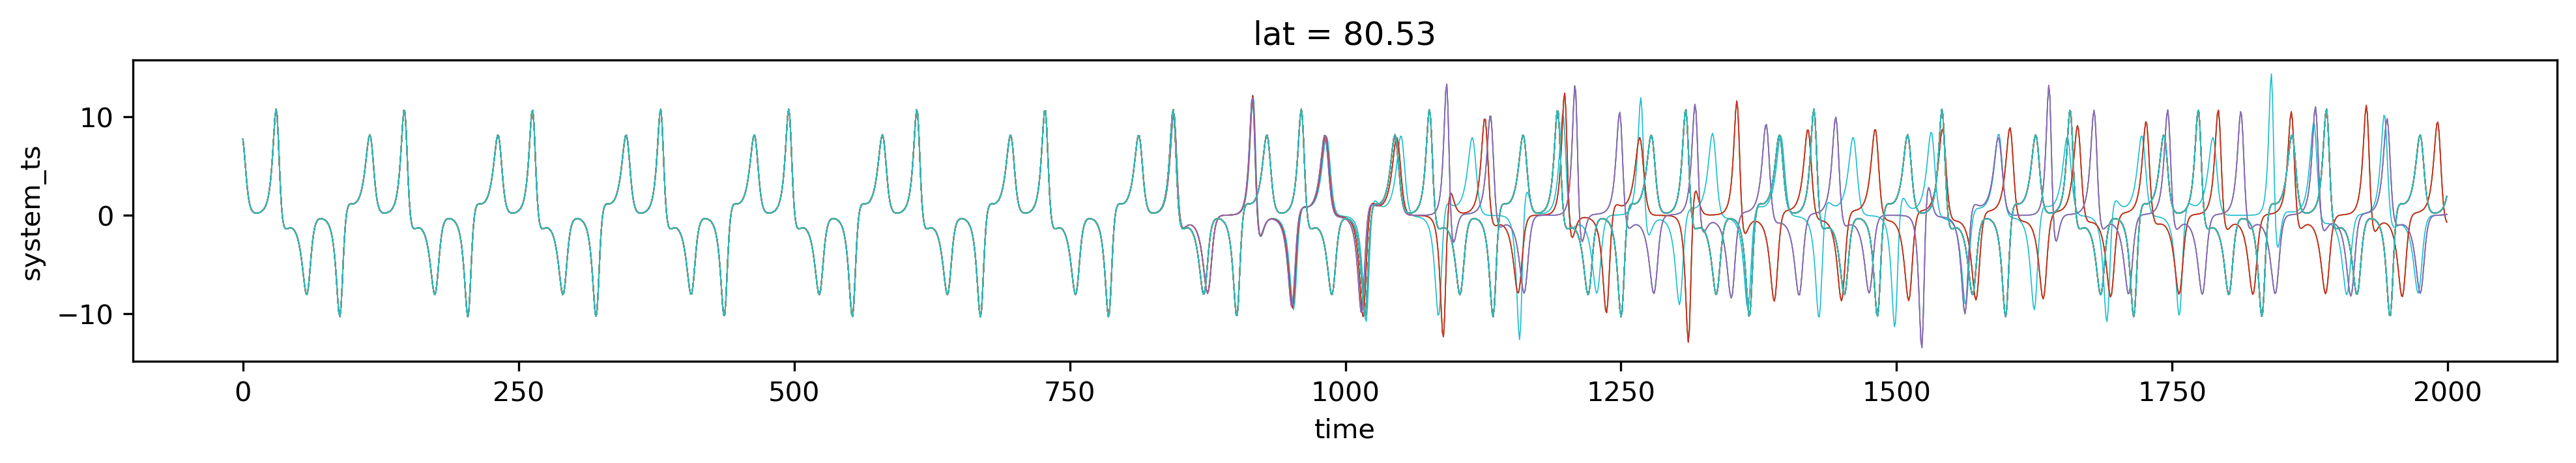

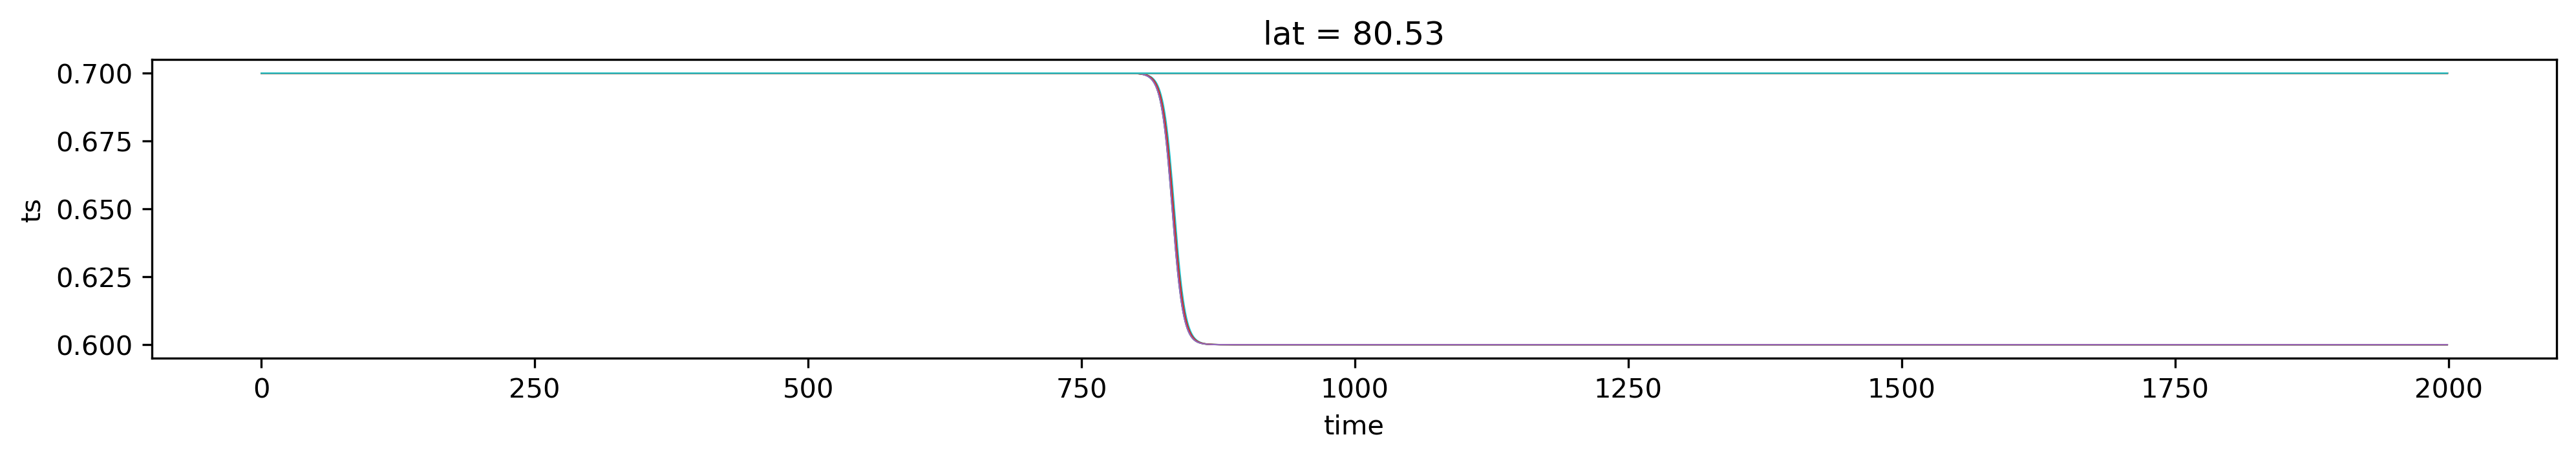

In [10]:
lat = 18

plt.figure(figsize=(16, 2))
pond.data.system_ts.isel(lat=lat, lon=range(40)).plot.line(x='time', lw=.4)
plt.legend().set_visible(False)

plt.figure(figsize=(16, 2))
pond.data.ts.isel(lat=lat, lon=range(40)).plot.line(x='time', lw=.5)
plt.legend().set_visible(False)

# Detecting nonlinear shifts with toad

In [11]:
from toad import TOAD
from toad.shifts import NONLINEAR
from sklearn.cluster import HDBSCAN
from toad.visualisation.toad_plotter import PlotConfig

In [12]:
data_ds = pond.data.system_ts.to_dataset(name="system_ts")
td = TOAD(data_ds)

now use toad to detect shifts (runs around 2-3 mins) and do clustering

In [13]:
# compute shifts
nonlinear_param_dict = {
    "window_size": 200,
    "window_step": 20,
    "recurrence_rate": 0.05,
    "embedding_dim": 2,
    "embedding_tau": 10,
    "recurrence_measure": 'transitivity',
    "lmin": 5
}

td.compute_shifts("system_ts", NONLINEAR(**nonlinear_param_dict))

INFO: New shifts variable system_ts_dts: min/mean/max=-0.731/-0.027/0.500 using 800 grid cells. Left behind 0.0% grid cells: 0 NaN, 0 constant.


In [14]:
# do clustering
td.compute_clusters(
    "system_ts",
    HDBSCAN(min_cluster_size=5),
    shift_threshold=0.3,             # choose threshold from [0,1]
    overwrite=True
)

INFO: New cluster variable system_ts_dts_cluster: Identified 2 clusters in 69 pts; Left behind 0.0% as noise (0 pts).


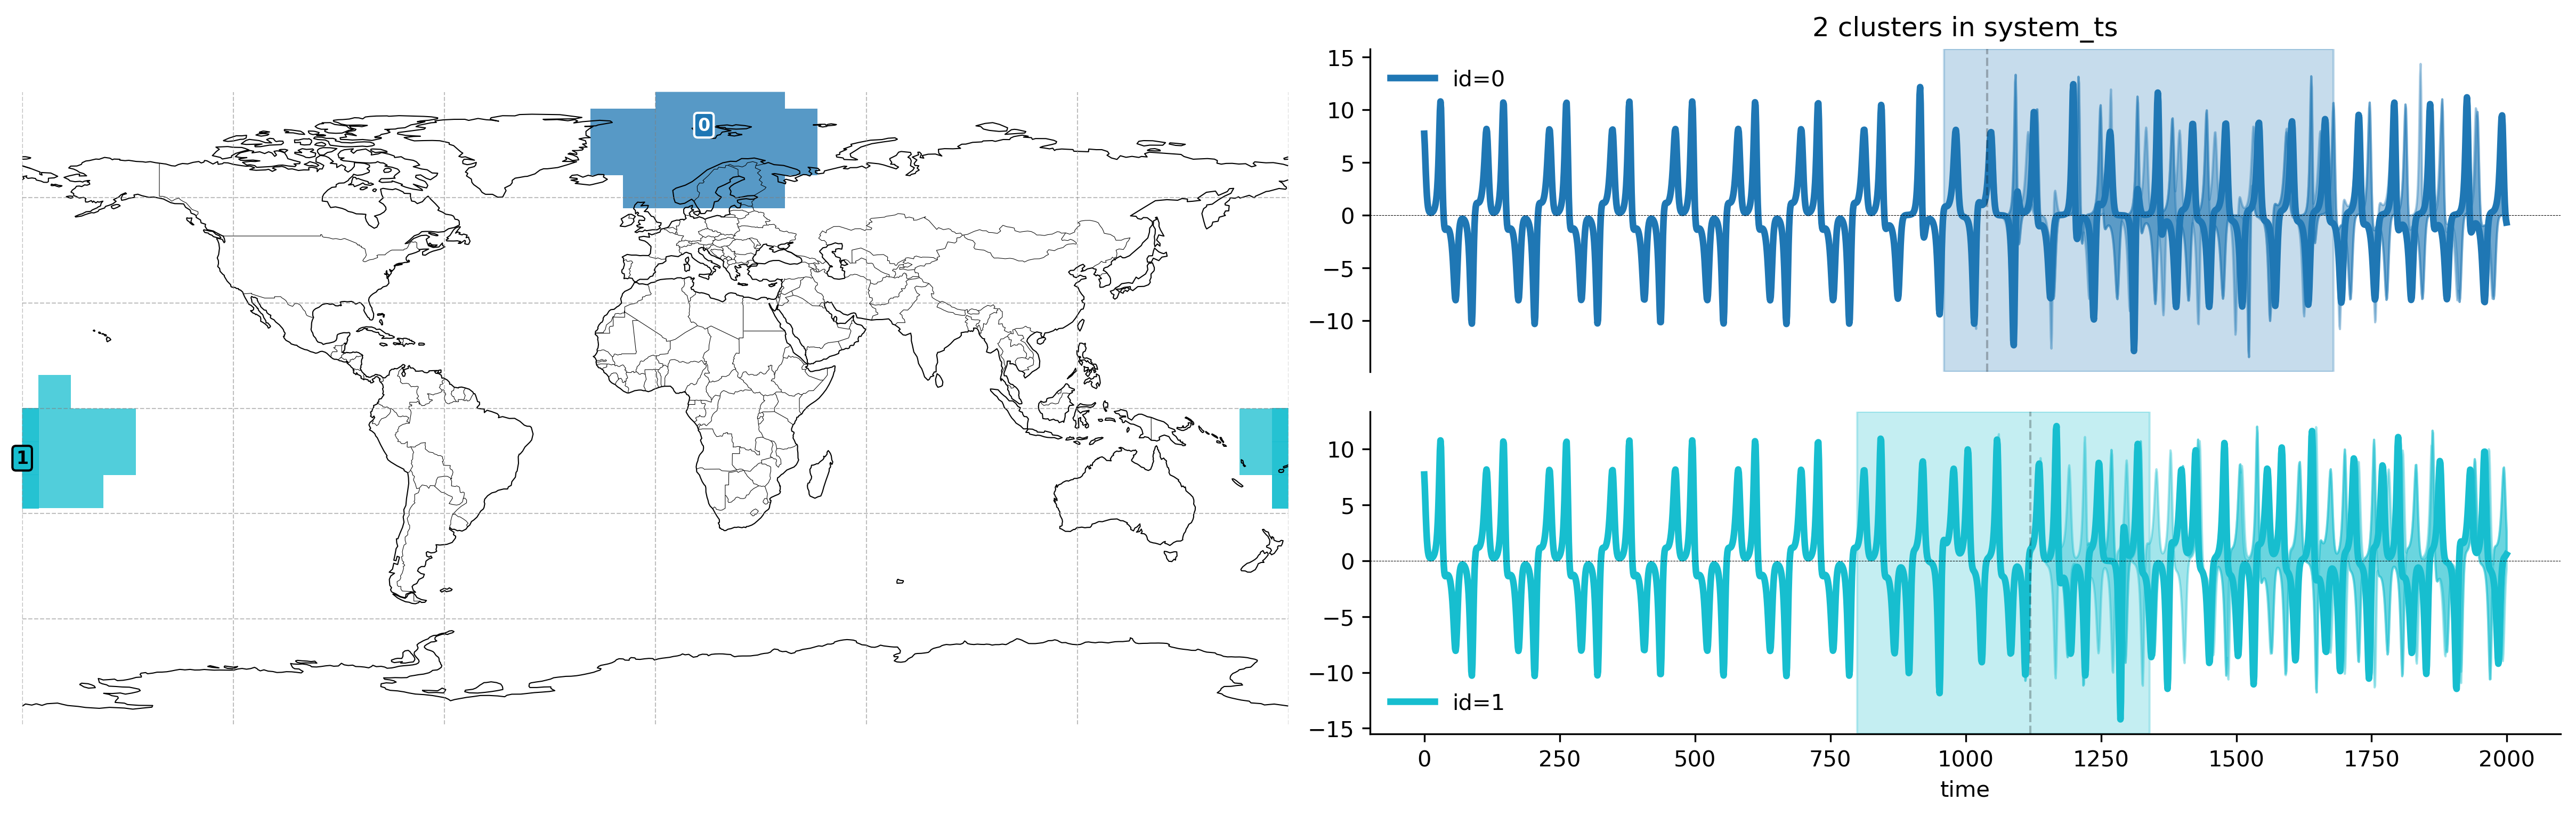

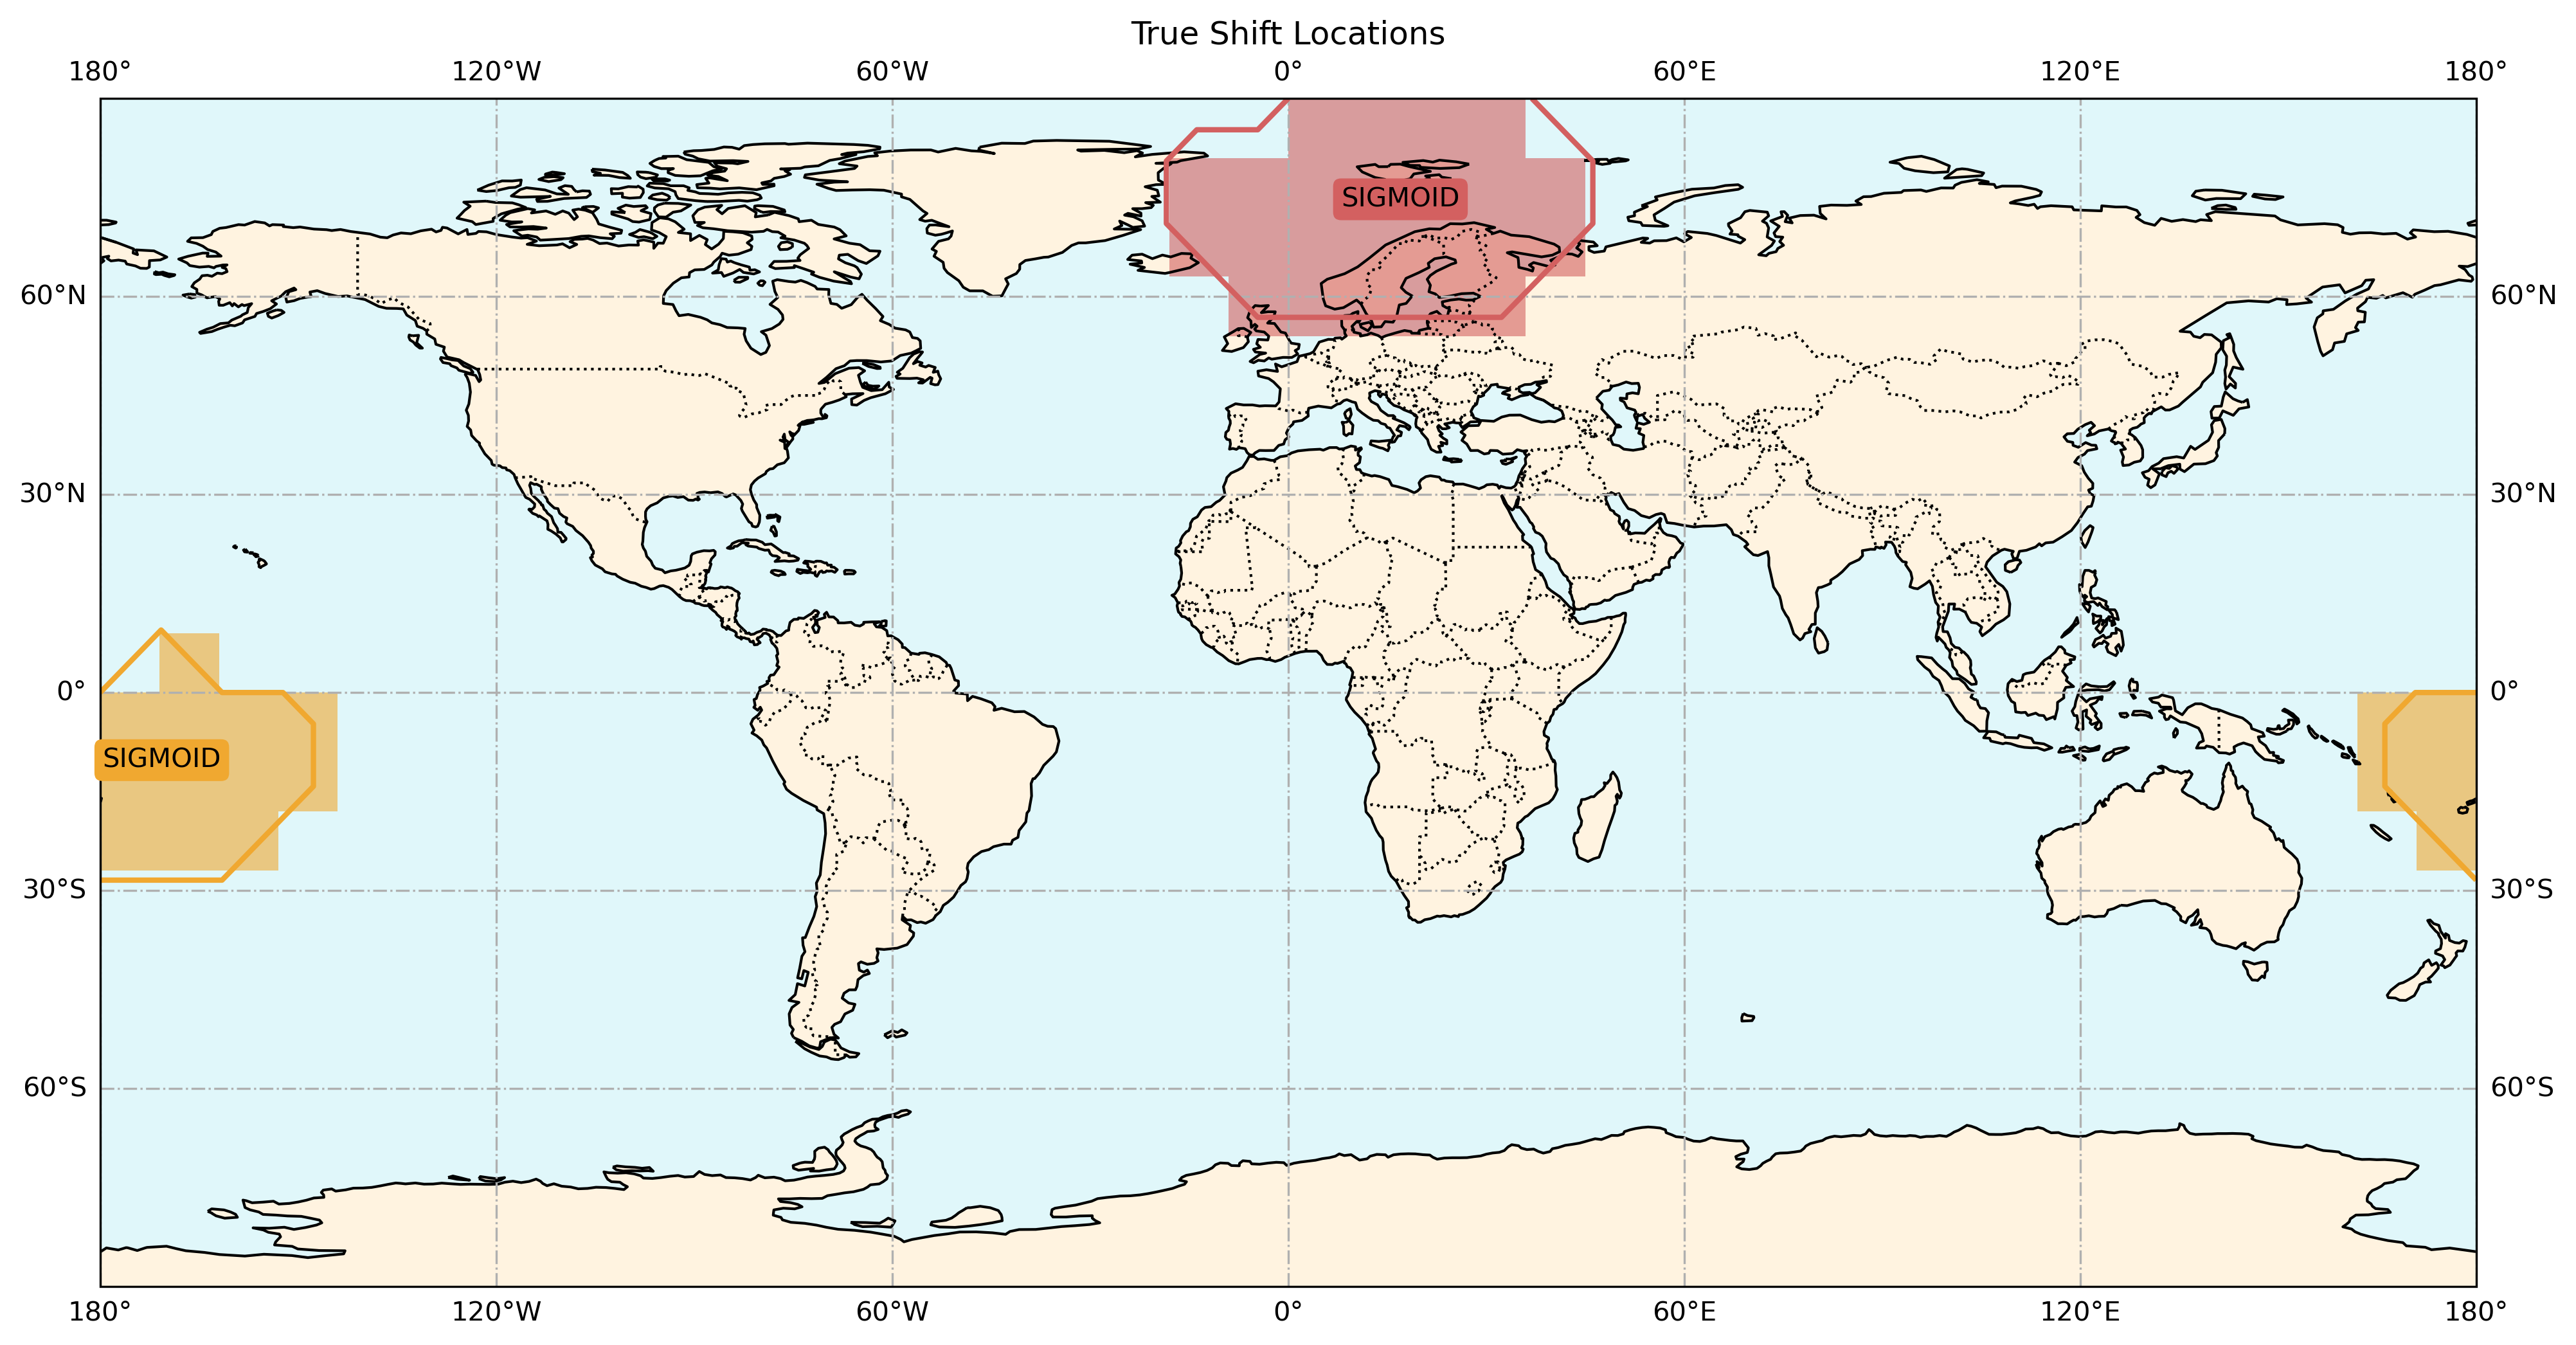

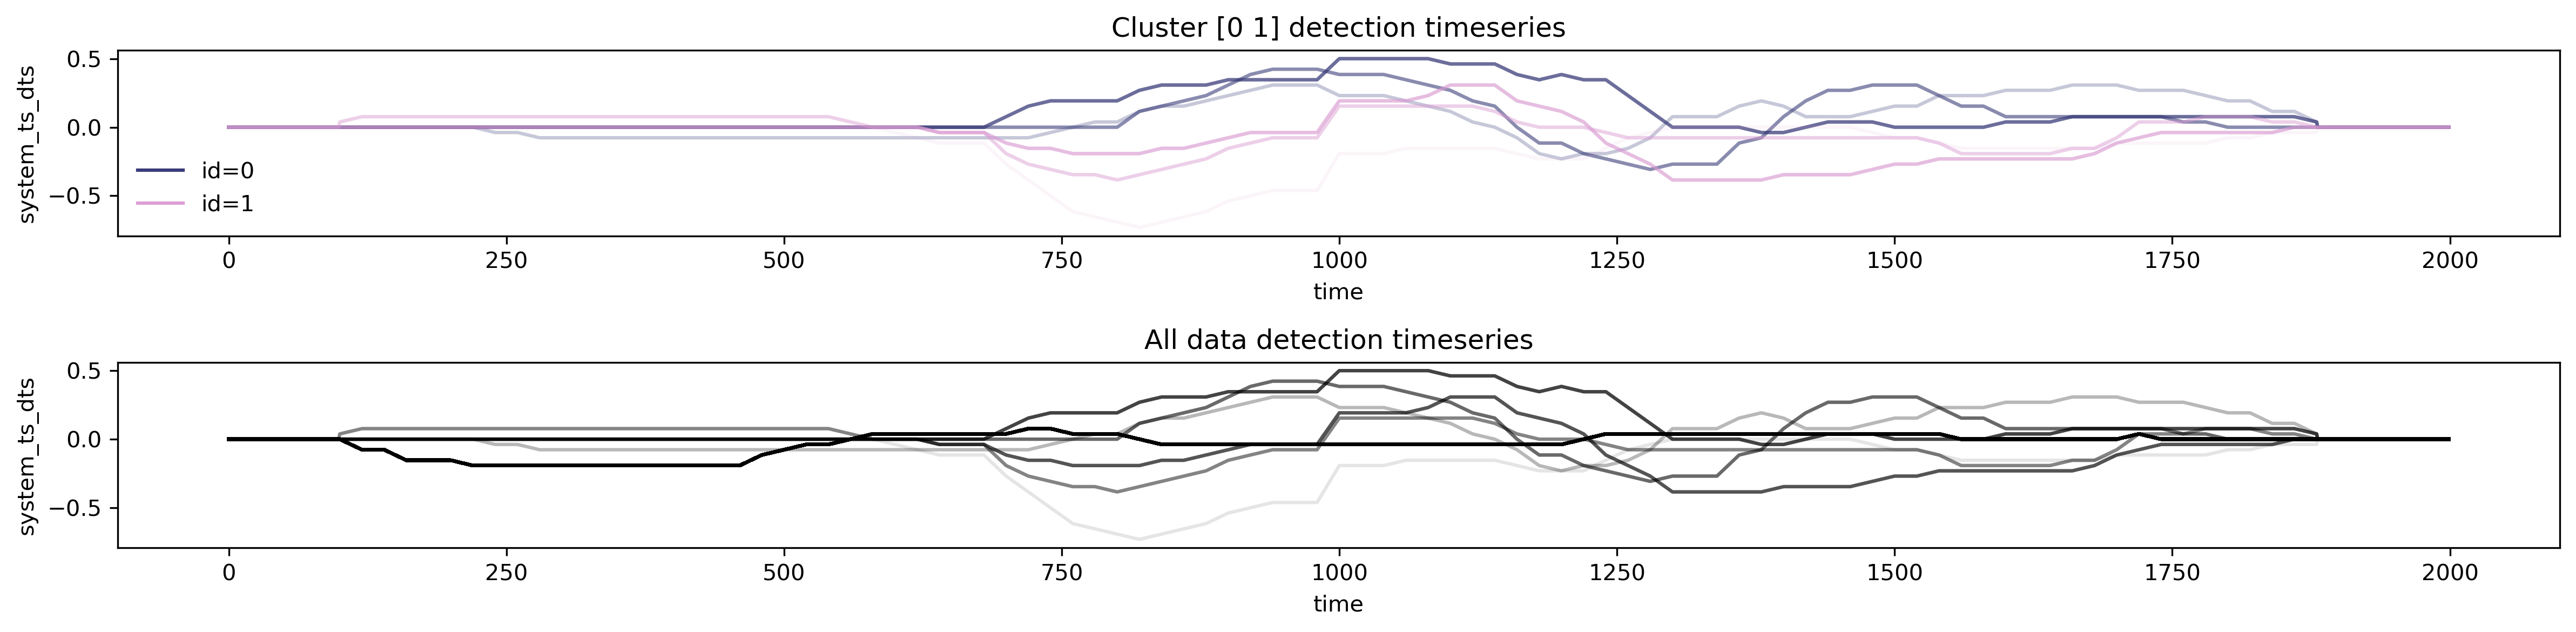

In [16]:
plt.rcParams["figure.dpi"] = 300

plotter = td.plotter(
    PlotConfig(
        map_frame=False,
        grid_labels=False,
    )
)

plotter.cluster_overview(
    "system_ts_dts",
    range(10),
    cmap="tab10",
    timeseries_kwargs={},
    map_kwargs={"add_contour": False},
    figsize=(16, 5),
)

# Plot true shift locations
# - Create a list of da_max for all relevant variables
pond.worldmap(
    title="True Shift Locations",
    shift_type=True,
)

# plot cluster timeseries
fig, axs = plt.subplots(2, 1, figsize=(16, 4))
plotter.cluster_timeseries("system_ts_dts", td.get_cluster_ids("system_ts"), ax=axs[0])

# plot data timeseries
td.data.system_ts_dts.toad.to_timeseries().plot.line(
    x="time", add_legend=False, color="k", alpha=0.1, ax=axs[1]
)
axs[0].set_title(f"Cluster {td.get_cluster_ids('system_ts')} detection timeseries")
axs[1].set_title("All data detection timeseries")
fig.tight_layout()